# Telecom Churn: Customer Risk and Contact Prioritization

## Business question

**Which 500 customers should a telecom company contact first, and how does the selected group compare with 500 customers chosen at random?**

This case study combines an analysis of customer churn patterns with a logistic regression model. Customers are ranked using a model-derived churn score multiplied by a customer-value proxy derived from their usage charges. The contact budget is fixed at 500 customers.

## Results at a glance

The saved evaluation uses a held-out sample of 1,000 customers, including 141 who churned.

| Measure | Saved result |
|---|---:|
| Churners in the top 500 | 124 of 141 |
| At-risk revenue captured in the top 500 | $8,392 of $9,207 |
| Expected capture with 500 random contacts | $4,604 |
| Lift over random contacts | 1.82x |
| Test ROC-AUC | 0.829 |
| Test average precision | 0.469 |

Here, captured at-risk revenue means the usage charges of actual churners included in the selected group. It is not revenue shown to have been retained by outreach.

## Reading guide

1. [Customer data and quality checks](#data-and-quality)
2. [Patterns associated with churn](#churn-patterns)
3. [Model development](#model-development)
4. [Model performance](#model-performance)
5. [Customer characteristics in the fitted model](#model-characteristics)
6. [Prioritizing 500 contacts](#contact-prioritization)
7. [Findings and limitations](#findings-and-limitations)

The project README contains the file guide and setup instructions.

<a id="data-and-quality"></a>

## 1. Customer data and quality checks

The local dataset contains 5,000 customer records, 19 input fields, and the target `Churn`. The inputs describe customer plans, usage, charges, and customer-service calls. The dataset's original source and license still need to be documented.

### Analysis environment

In [1]:
import pandas as pd 
import numpy as np 

import os

import matplotlib.pyplot as plt
import seaborn as sns

import missingno as msno

import churn_helpers as fpf

# ML libraries
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, RocCurveDisplay,
    average_precision_score, PrecisionRecallDisplay,
)

### Load the customer records

In [2]:
df = pd.read_csv('data/raw data/churn_all.csv')

### Check completeness and customer identifiers

Inspect the dataset structure and missing values, then check whether phone numbers identify unique customer records.

In [3]:
# basic data exploration
fpf.basic_exploration(df)

What is the shape (dimensions) of the dataframe?


'The dataframe has 5000 rows and 20 columns'

----------------------------------------------------------------------------------------------------
What are the first five rows of the dataframe?


,state,area_code,phone_number,international_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,Churn
0,KS,415,382-4657,no,yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,415,371-7191,no,yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,415,358-1921,no,no,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,408,375-9999,yes,no,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,415,330-6626,yes,no,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


----------------------------------------------------------------------------------------------------
What is a random sample of 5 rows from the dataframe?


...

----------------------------------------------------------------------------------------------------
How many unique values does each column have?


Churn                               2
international_plan                  2
voice_mail_plan                     2
area_code                           3
number_customer_service_calls      10
total_intl_calls                   21
number_vmail_messages              48
state                              51
total_day_calls                   124
total_eve_calls                   126
total_night_calls                 131
total_intl_minutes                170
total_intl_charge                 170
total_night_charge               1028
total_eve_charge                 1659
total_night_minutes              1853
total_eve_minutes                1879
total_day_charge                 1961
total_day_minutes                1961
phone_number                     5000
dtype: int64

----------------------------------------------------------------------------------------------------
What are the unique values of each column?


,0
state,"[KS, OH, NJ, OK, AL, MA, MO, LA, WV, IN, RI, I..."
area_code,"[415, 408, 510]"
phone_number,"[ 382-4657, 371-7191, 358-1921, 375-9999, ..."
international_plan,"[ no, yes]"
voice_mail_plan,"[ yes, no]"
number_vmail_messages,"[25, 26, 0, 24, 37, 27, 33, 39, 30, 41, 28, 34..."
total_day_minutes,"[265.1, 161.6, 243.4, 299.4, 166.7, 223.4, 218..."
total_day_calls,"[110, 123, 114, 71, 113, 98, 88, 79, 97, 84, 1..."
total_day_charge,"[45.07, 27.47, 41.38, 50.9, 28.34, 37.98, 37.0..."
total_eve_minutes,"[197.4, 195.5, 121.2, 61.9, 148.3, 220.6, 348...."


----------------------------------------------------------------------------------------------------


How many null values does each column have?


state                            0
area_code                        0
number_customer_service_calls    0
total_intl_charge                0
total_intl_calls                 0
total_intl_minutes               0
total_night_charge               0
total_night_calls                0
total_night_minutes              0
total_eve_charge                 0
total_eve_calls                  0
total_eve_minutes                0
total_day_charge                 0
total_day_calls                  0
total_day_minutes                0
number_vmail_messages            0
voice_mail_plan                  0
international_plan               0
phone_number                     0
Churn                            0
dtype: int64

----------------------------------------------------------------------------------------------------
What is the percentage of null values per column?


,Column,Percentage
0,state,0.0
1,area_code,0.0
2,number_customer_service_calls,0.0
3,total_intl_charge,0.0
4,total_intl_calls,0.0
5,total_intl_minutes,0.0
6,total_night_charge,0.0
7,total_night_calls,0.0
8,total_night_minutes,0.0
9,total_eve_charge,0.0


----------------------------------------------------------------------------------------------------
Visualization of null values:


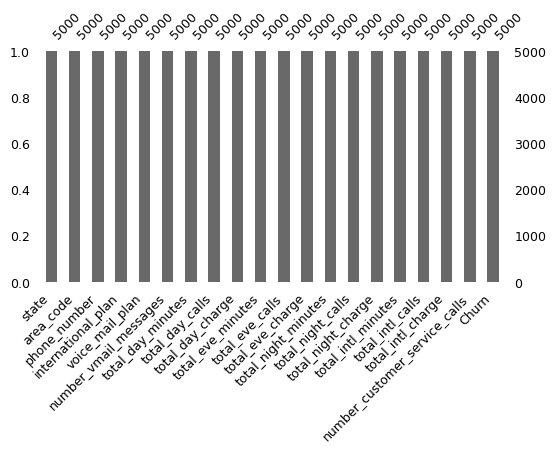

----------------------------------------------------------------------------------------------------
Visualization of the null values pattern:


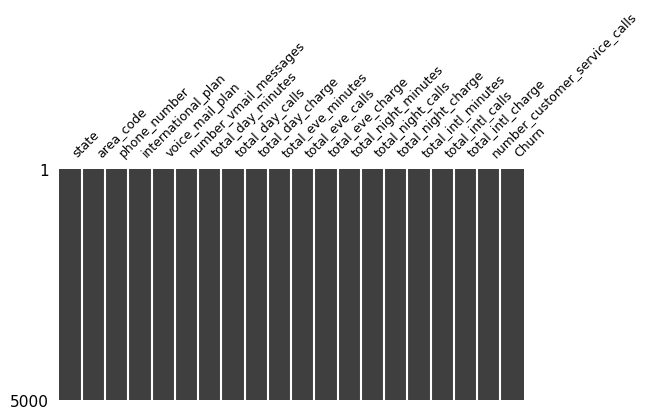

----------------------------------------------------------------------------------------------------


In [4]:
# null exploration
fpf.null_exploration(df)

In [5]:
# duplicate exploration
# each row corresponds to a single customer, therefore, phone numbers should be unique
df['phone_number'].duplicated().sum()

np.int64(0)

<a id="churn-patterns"></a>

## 2. Patterns associated with churn

### Overall churn rate

In [6]:
df['Churn'].value_counts(normalize=True)

Churn
False    0.8586
True     0.1414
Name: proportion, dtype: float64

The target is imbalanced: approximately 14% of customers churned. This needs to be considered when choosing the model and evaluation metrics.

### Churn rate by state

In [7]:
# do some states have significantly higher churn rates than others?
churn_rate_by_state = df.groupby('state').Churn.agg(['count','sum'])

In [8]:
churn_rate_by_state['churn rate'] = churn_rate_by_state['sum'] / churn_rate_by_state['count']
churn_rate_by_state = churn_rate_by_state.drop(['count', 'sum'], axis=1)
churn_rate_by_state = churn_rate_by_state.sort_values(by='churn rate', ascending=False)

Text(0, 0.05084745762711865, ' Min: 0.051')

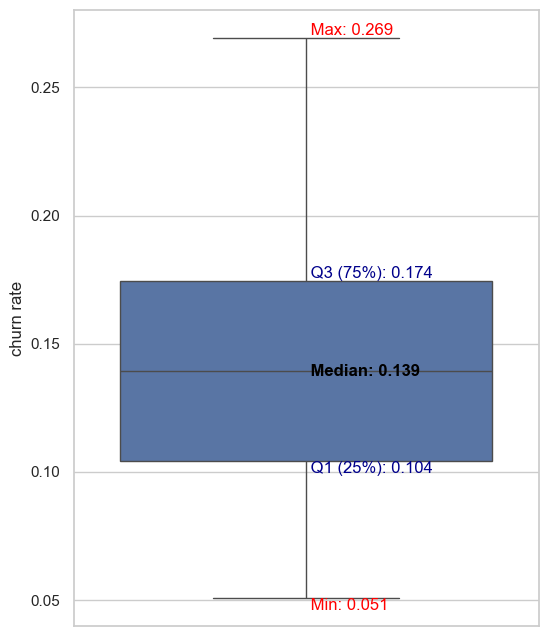

In [9]:
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(6, 8))
sns.boxplot(data=churn_rate_by_state, y='churn rate')

stats = churn_rate_by_state['churn rate'].describe()
min_val = stats['min']
q1 = stats['25%']
median = stats['50%']
q3 = stats['75%']
max_val = stats['max']

x_pos = 0

ax.text(x_pos, median, f' Median: {median:.3f}', va='center', fontweight='bold', color='black')
ax.text(x_pos, q3, f' Q3 (75%): {q3:.3f}', va='bottom', color='darkblue')
ax.text(x_pos, q1, f' Q1 (25%): {q1:.3f}', va='top', color='darkblue')
ax.text(x_pos, max_val, f' Max: {max_val:.3f}', va='bottom', color='red')
ax.text(x_pos, min_val, f' Min: {min_val:.3f}', va='top', color='red')

In [10]:
df['state'].value_counts().describe()

count     51.000000
mean      98.039216
std       16.562561
min       52.000000
25%       89.000000
50%       98.000000
75%      104.500000
max      158.000000
Name: count, dtype: float64

The observed churn rate by state ranges from approximately 0.05 to 0.27. The highest rate is more than five times the lowest. However, each state has about 98 customers on average, which may be insufficient to establish whether the differences are statistically significant.

### Churn rate by international plan

In [11]:
df_international_churn = df.groupby('international_plan').Churn.agg(['count','sum'])
df_international_churn['churn rate'] = df_international_churn['sum']/df_international_churn['count']

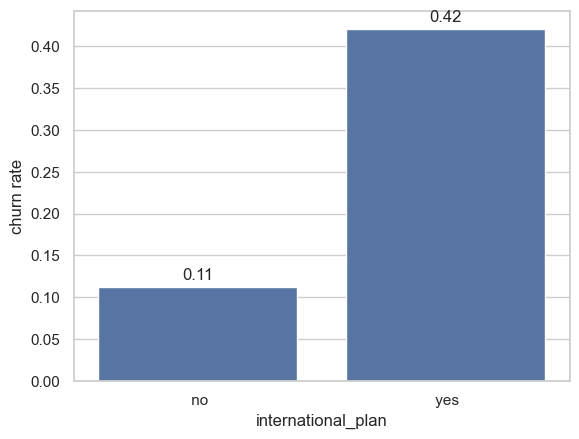

In [12]:
ax = sns.barplot(data=df_international_churn, x='international_plan', y='churn rate')
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
plt.show()

The observed churn rate is approximately 42% for customers with an international plan (473 customers), compared with 11% for those without one. This is a difference of about 31 percentage points. No statistical significance test was performed.

### Churn rate by voice mail plan

In [13]:
df_voicemail_churn = df.groupby('voice_mail_plan').Churn.agg(['count','sum'])
df_voicemail_churn['churn rate'] = df_voicemail_churn['sum']/df_voicemail_churn['count']

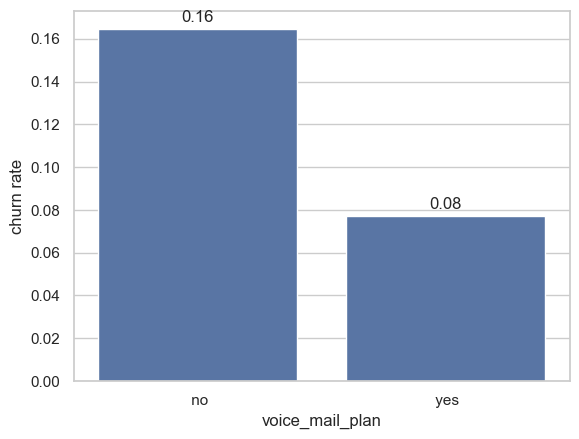

In [14]:
ax = sns.barplot(data=df_voicemail_churn, x='voice_mail_plan', y='churn rate')
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
plt.show()

Customers without a voice-mail plan have an observed churn rate of approximately 16.45%, compared with 7.71% for those with a plan. Churn is therefore about twice as common in the group without a plan. This group difference is smaller than the international-plan comparison.

### Churn rate by number of customer service calls

In [15]:
df_cscalls_churn = df.groupby('number_customer_service_calls').Churn.agg(['count','sum'])
df_cscalls_churn['churn rate'] = df_cscalls_churn['sum']/df_cscalls_churn['count']

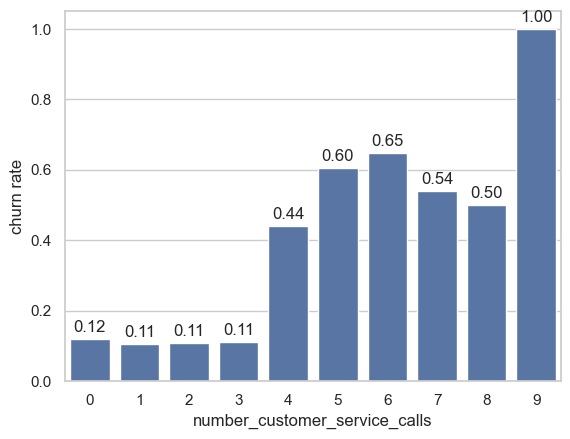

In [16]:
ax =sns.barplot(data=df_cscalls_churn, x='number_customer_service_calls', y='churn rate')
ax.bar_label(ax.containers[0], fmt="%.2f", padding=3)
plt.show()

The observed churn rate rises from about 11% with three customer-service calls to 44% with four calls, a difference of roughly 33 percentage points. The 100% rate at nine calls comes from only two customers and should not be generalized.

<a id="model-development"></a>

## 3. Model development

The following sections document the model choice, input selection, preprocessing, train/test split, and tuning process.

### Model choice

Logistic regression provides scores through `predict_proba` for ranking customers, along with coefficients for examining associations in the fitted model. Calibration has not been evaluated. With `class_weight='balanced'`, these scores should not be presented as verified individual churn probabilities.

Three choices guide the implementation:

- **Inputs:** remove `phone_number` and `area_code`, retain charges instead of the nearly redundant minutes variables, and omit `state` as described in the exploration and feature-selection sections.
- **Tuning:** select the regularization strength `C` using `LogisticRegressionCV` and stratified folds.
- **Optimization:** use `average_precision` to assess ranking of the minority churn class. With about 14% churn, predicting no churn for every customer would give approximately 86% accuracy without identifying any churners.

### Feature selection and redundant inputs

In [17]:
# we don't need these columns
drop_columns = ['state', 'area_code', 'phone_number']
df = df.drop(columns=drop_columns)

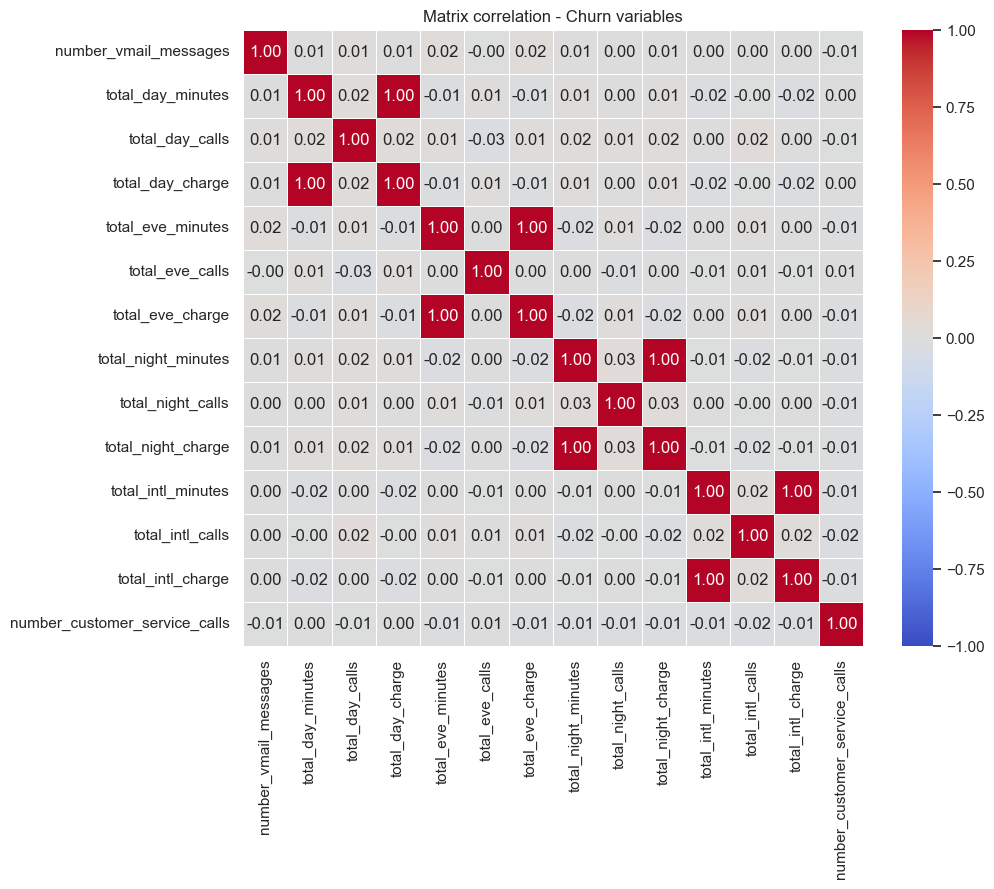

In [18]:
df_numeric = df.select_dtypes('number').copy()
corr_matrix = df_numeric.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True, 
    cmap="coolwarm",
    fmt=".2f", 
    linewidths=0.5,
    vmin=-1,
    vmax=1,
)

plt.title("Matrix correlation - Churn variables")

plt.show()

In [19]:
# to avoid multicolinearity we drop the following columns:
columns_to_drop = ['total_day_minutes', 'total_eve_minutes', 'total_night_minutes', 'total_intl_minutes']
df = df.drop(columns=columns_to_drop)

The correlation heatmap above shows `total_X_minutes` and `total_X_charge`
pairs correlated at ~1.0 for every time-of-day segment — expected, since
charge is simply minutes billed at a fixed rate. Keeping both would add
unstable, redundant coefficients to a linear model without any new
information, so I keep `charge` (closer to the business-relevant unit,
revenue) and drop the corresponding `minutes` columns

### Encoding and scaling

In [20]:
categorical_cols = ['international_plan', 'voice_mail_plan']
numeric_cols = df.select_dtypes('number').columns.tolist()
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'),categorical_cols),
        ('num', StandardScaler(with_mean=False), numeric_cols)
    ]
)

### Held-out train/test split

In [21]:
x = df[df.columns.drop('Churn')]
y = df['Churn']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

### Pipeline and hyperparameter tuning

In [22]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

logreg = LogisticRegressionCV(
    class_weight='balanced',
    scoring='average_precision',
    cv=cv_strategy,
    max_iter=2000,   
    random_state=42
)

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('logreg', logreg),
])

### Fit the model and score the test set

In [23]:
pipeline.fit(x_train, y_train)

# .predict_proba returns two columns: P(class=False), P(class=True)
# Use the churn-class score for ranking; calibration has not been verified.

y_proba = pipeline.predict_proba(x_test)[:, 1]
y_pred = pipeline.predict(x_test)  # hard 0/1 label at the default 0.5 threshold

/opt/anaconda3/envs/science_env/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1780: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/opt/anaconda3/envs/science_env/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1823: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(


<a id="model-performance"></a>

## 4. Model performance

With `predict_proba` computed, evaluation checks two things: how well the
model performs at a fixed 50% cutoff (`classification_report`, `confusion matrix`), 
and how well it ranks customers regardless of any cutoff
(`ROC-AUC`,`PR-AUC`). The second matters more here, since the business
question is about a ranked list, not a fixed threshold.

              precision    recall  f1-score   support

    No churn       0.94      0.78      0.85       859
       Churn       0.34      0.70      0.46       141

    accuracy                           0.77      1000
   macro avg       0.64      0.74      0.66      1000
weighted avg       0.86      0.77      0.80      1000



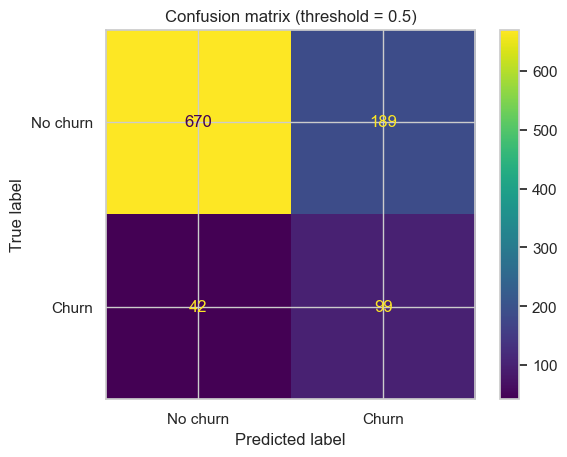

ROC-AUC: 0.829
Average precision: 0.469


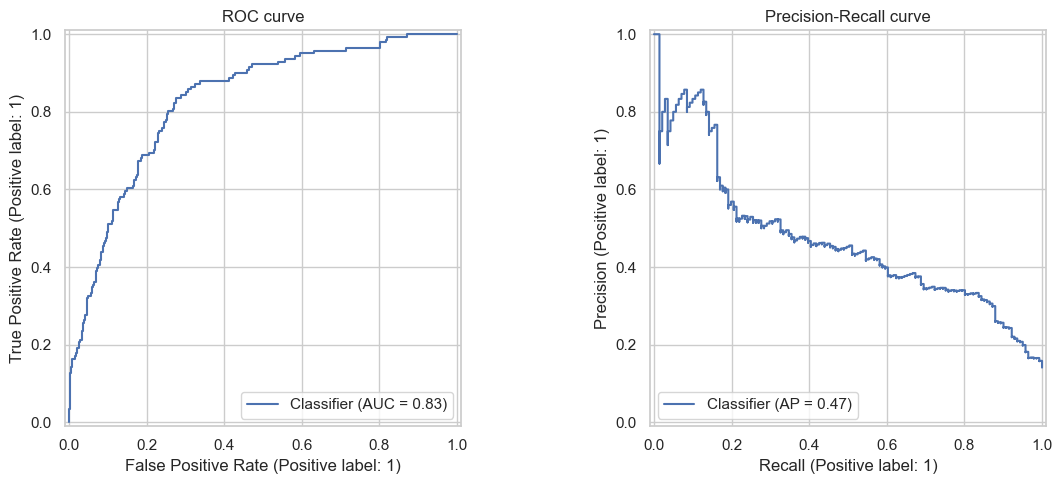

No-skill average-precision reference (churn prevalence): 0.141


In [24]:
print(classification_report(y_test, y_pred, target_names=['No churn', 'Churn']))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['No churn','Churn'])
plt.title('Confusion matrix (threshold = 0.5)')
plt.show()

roc_auc = roc_auc_score(y_test, y_proba)
pr_auc = average_precision_score(y_test, y_proba)
print(f"ROC-AUC: {roc_auc:.3f}")
print(f"Average precision: {pr_auc:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[0])
axes[0].set_title('ROC curve')
PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[1])
axes[1].set_title('Precision-Recall curve')
plt.tight_layout()
plt.show()

# Naive baseline for context — this is your "vs. random" business question,
# computed here as a sanity check: a model with no skill has PR-AUC roughly
# equal to the churn rate itself (~0.14). Compare pr_auc above to that.
print(f"No-skill average-precision reference (churn prevalence): {y_test.mean():.3f}")

### Interpreting the test-set metrics

Recall for `Churn` (0.70) and precision (0.34) describe the default 0.5 cutoff. Class weighting gives the minority class more emphasis during fitting. Prioritizing missed churners over unnecessary contacts is a case assumption; contact costs and the financial effect of missed churn are not measured.

ROC-AUC (0.829) describes the model's ability to rank a churner above a non-churner. Average precision (0.469), compared with a churn prevalence of 0.141, provides additional evidence of ranking signal under class imbalance. The contact-list comparison below evaluates the specific 500-customer budget.

### Cross-validation on the training data

A single train/test split can be noisy with this few churn cases, so I
validate with 5-fold stratified cross-validation (stratified to keep the
~14% churn ratio in every fold) around the full pipeline

In [25]:
cv_results = cross_validate(
    pipeline, x_train, y_train,
    cv=cv_strategy,
    scoring=['roc_auc', 'average_precision', 'recall', 'precision'],
)

for metric in ['test_roc_auc', 'test_average_precision', 'test_recall', 'test_precision']:
    print(f"{metric}: {cv_results[metric].mean():.3f}  (+/- {cv_results[metric].std():.3f})")

/opt/anaconda3/envs/science_env/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1780: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/opt/anaconda3/envs/science_env/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1823: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set it to `True` to silence this warning during the transition period while keeping the deprecated behavior for the time being. The default value of use_legacy_attributes will change from True to False in scikit-learn 1.10. See the docstring of LogisticRegressionCV for more details.
  warnings.warn(
/opt/anaconda3/envs

test_roc_auc: 0.829  (+/- 0.022)
test_average_precision: 0.454  (+/- 0.040)
test_recall: 0.783  (+/- 0.048)
test_precision: 0.360  (+/- 0.021)


### Performance across folds

The five-fold mean ROC-AUC is 0.829, with a standard deviation of 0.022. The variation across these folds gives context for the single test split, but does not establish that performance is independent of the split.

**Validation limitation:** preprocessing is fitted on each outer training fold before the internal folds in `LogisticRegressionCV` select `C`. Consequently, internal tuning folds share the fitted scaling. The held-out test set remains outside pipeline fitting. The size of any effect on tuning has not been measured. No alternative model or tuning method is introduced here.

The earlier state-versus-no-state scores (0.826 and 0.829) are not reproduced as a controlled comparison in this notebook and do not establish which input choice is better.

<a id="model-characteristics"></a>

## 5. Customer characteristics in the fitted model

/var/folders/6h/76s5lftj1d10282hykft0lm80000gn/T/ipykernel_68341/102488368.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


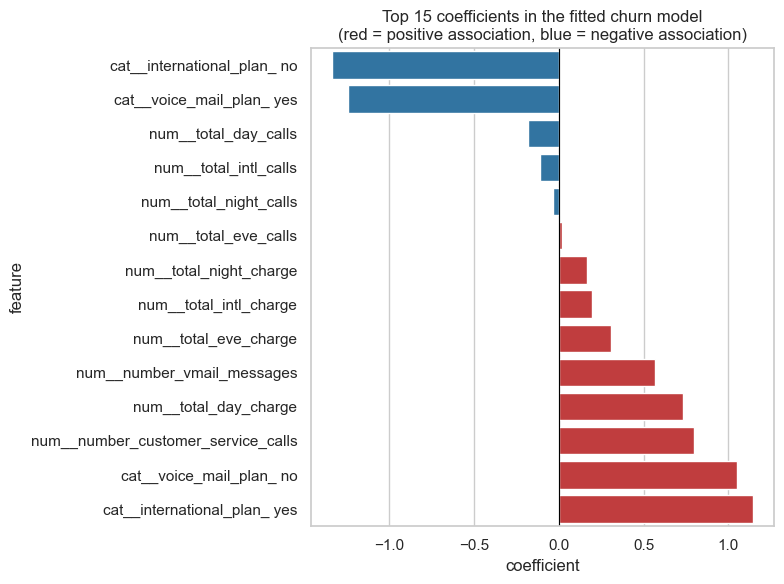

In [26]:
feature_names = pipeline.named_steps['preprocessor'].get_feature_names_out()
coefs = pipeline.named_steps['logreg'].coef_[0]

coef_df = pd.DataFrame({'feature': feature_names, 'coefficient': coefs})
coef_df['abs_coefficient'] = coef_df['coefficient'].abs()
top_features = coef_df.sort_values('abs_coefficient', ascending=False).head(15)

plt.figure(figsize=(8, 6))
sns.barplot(
    data=top_features.sort_values('coefficient'),
    x='coefficient', y='feature',
    palette=['#d62728' if c > 0 else '#1f77b4' for c in top_features.sort_values('coefficient')['coefficient']]
)
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Top 15 coefficients in the fitted churn model\n(red = positive association, blue = negative association)')
plt.tight_layout()
plt.show()

### Interpreting the strongest signals

The fitted coefficients and exploratory comparisons suggest the following associations:

**Observed associations** (consistent with the exploratory comparisons; group sizes vary and no formal confidence assessment was performed):
- Having an **international plan** is the single strongest predictor of
  churn — customers with one churn noticeably more often than those without.
- **Not** having a **voice mail plan** is associated with higher churn.
- More **customer service calls** is associated with higher churn — likely
  a proxy for unresolved problems or dissatisfaction.
- Higher **total day charge** (heavier daytime usage) is associated with
  somewhat higher churn — possibly price sensitivity among heavy users.

<a id="contact-prioritization"></a>

## 6. Prioritizing 500 contacts

The contact list considers both the model's churn score and customer value. Ranking only by the churn score would give the same priority to customers with very different usage charges.

The dataset does not include profit or contact costs, so this analysis uses total monthly charges (day, evening, night, and international) as a customer-value proxy. Customers are ranked by the existing calculation `churn_probability × customer_value`. The code calls this variable `expected_value_at_risk`; because probability calibration has not been checked, it is used here as a ranking score rather than a verified economic expectation.

The code below compares the top 500 with a uniform random selection of 500 from the same held-out sample. The random baseline is the selected share of customers multiplied by the total observed at-risk value.

This retrospective comparison measures the charges associated with actual churners in each group. There is no outreach experiment or measured retention outcome in this dataset.

In [27]:
# Value-weighted prioritization: combine likelihood of churning with
# how much revenue that customer represents, rather than probability alone.
customer_value = (x_test['total_day_charge'] + x_test['total_eve_charge']
                   + x_test['total_night_charge'] + x_test['total_intl_charge'])

ranked = x_test.copy()
ranked['churn_probability'] = y_proba
ranked['actual_churn'] = y_test.values
ranked['customer_value'] = customer_value
ranked['expected_value_at_risk'] = ranked['churn_probability'] * ranked['customer_value']

ranked_by_value = ranked.sort_values('expected_value_at_risk', ascending=False)
top_500_value = ranked_by_value.head(500)

# How many actual churners are in this value-weighted top 500?
churners_captured_value = top_500_value['actual_churn'].sum()

# How much of the total revenue that's actually "at risk" (i.e. belongs to
# real churners) does this top 500 capture?
total_at_risk_value = ranked.loc[ranked['actual_churn'], 'customer_value'].sum()
captured_value = top_500_value.loc[top_500_value['actual_churn'], 'customer_value'].sum()

# Expected capture if instead we just picked 500 customers at random
random_expected_churners = 500 * ranked['actual_churn'].mean()
random_expected_value = (500 / len(ranked)) * total_at_risk_value

print(f"Churners captured (value-weighted top 500): {churners_captured_value}")
print(f"  vs. expected at random: {random_expected_churners:.1f}")
print()
print(f"At-risk revenue captured: ${captured_value:,.0f} of ${total_at_risk_value:,.0f} total")
print(f"  vs. expected at random: ${random_expected_value:,.0f}")
print(f"Revenue-based lift over random: {captured_value / random_expected_value:.2f}x")

Churners captured (value-weighted top 500): 124
  vs. expected at random: 70.5

At-risk revenue captured: $8,392 of $9,207 total
  vs. expected at random: $4,604
Revenue-based lift over random: 1.82x


<a id="findings-and-limitations"></a>

## 7. Findings and limitations

### What characterizes customers who churn?

The main signals identified in the analysis are having an international plan, not having a voice-mail plan, more customer-service calls, and higher daytime charges. The observed voice-mail churn rates are 16.45% without a plan and 7.71% with one.

### How well does the model rank customers?

Test ROC-AUC is 0.829 and average precision is 0.469. The five-fold training-data evaluation gives a mean ROC-AUC of 0.829. These metrics assess model ranking; they do not establish that each predicted probability equals the customer's true churn risk. No probability-calibration check has been performed. Internal tuning also shares fitted scaling across its folds, as described in the validation section.

### Which 500 customers are prioritized?

The existing ranking combines the churn score and usage-charge proxy. In the held-out sample, the top 500 include 124 of the 141 actual churners and $8,392 of $9,207 in observed at-risk charges.

### How does this compare with random selection?

The expected at-risk charges represented in 500 random contacts are $4,604. The selected group contains 1.82 times that value, or approximately 82% more, within the same contact budget. This is a retrospective selection result, not evidence of retained customers, saved revenue, or a profitable outreach campaign.

### Limitations and next steps

- Usage charges are a value proxy; margin, customer lifetime value, and contact costs are not available.
- Class weighting may affect probability calibration. The model outputs are used for ranking, and calibration remains an unimplemented follow-up.
- The value comparison uses one held-out sample of 1,000 customers and one contact budget of 500. Results at other budgets are not evaluated.
- No retention intervention was tested. The business effect of contacting the selected customers is unknown.
- Dataset provenance and licensing still need confirmation.

Potential future work includes checking calibration, comparing other contact budgets, and using better value and cost data. Those extensions are not implemented in this project.